# 05 — QTM differential conductance with a twisted-bilayer-graphene sample (SLG tip | hBN | TBG)

Wei *et al.* (PRB **112**, 155157) Eq. (33) at $T=0$:

$$\frac{dI}{dV}(V,\theta)=e^2\Gamma\sum_{\lambda\rho}\Lambda_\lambda(\mathbf{K}_\theta)\,A^S_{\lambda\rho}(\mathbf{K}_\theta,eV)\,\Lambda_\rho(\mathbf{K}_\theta)^*,
\qquad \Lambda_\lambda(\mathbf{K}_\theta)=u^\lambda_{\mathbf{K}_\theta,tA}+u^\lambda_{\mathbf{K}_\theta,tB}.$$

* $\mathbf{K}_\theta=O(\theta)\mathbf{K}_{\rm top}$ is the tip Dirac point ($\theta$ = tip–top-layer twist): at
  $\theta=0$ the tip probes the top-layer Dirac point $\kappa_{\rm top}$, at $\theta=\theta_{\rm TBG}$ the bottom one,
  at $\theta=-\theta_{\rm TBG}$ the $\gamma$ point of the neighbouring moiré zone;
* the momentum is **not folded** in the matrix element: $\Lambda$ uses the plane-wave component of the Bloch
  state at the *unfolded* momentum, $\mathbf{K}_\theta=\mathbf{k}+\mathbf{G}$ (this is what makes the QTM an
  extended-zone probe);
* $A^S_{\lambda\rho}$ is the band-matrix G0W spectral function at the folded $\mathbf{k}$.

Notes: Sec. 7 (derivation and kinematics) and Sec. 8.5 (these results).

In [1]:
import sys, os, time
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from g0w.models import tbg_model as tm, tbg_stack as tst, tbg_self_energy as tse
from g0w import qtm, spectral
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

N_SITES, N_BANDS = 18, 4
params = tm.TBGParams(theta_deg=1.20, uAB=0.117, uAA_ratio=0.7, n_sites=N_SITES, n_bands=N_BANDS)
tbg = tm.build_tbg(params, verbose=True)
fr = tm.model_frame(tbg)

  TBG theta=1.2deg, uAB=117 meV, filling=0, n_sites=18, 8 bands
  n_k = 324, n_q = 324, n_G = 1, G_moire = 0.6177 nm^-1
  alpha = 0.5640, v_n = 0.0103 eV nm, eta = 0.708 meV
  mu = +1.810 meV   [12.5 s]


## 1. The tip trajectory in the moiré Brillouin zone

max snapping error: 0.54 mesh spacings
theta = +0.00 deg: k = [-0.3088  0.1783],  |k - K_top| = 0.0000, |k - K_bot| = 0.3566,  |k| = 0.3566 (|G_M| = 0.6177)
theta = +1.20 deg: k = [-0.3088 -0.1783],  |k - K_top| = 0.3566, |k - K_bot| = 0.0000,  |k| = 0.3566 (|G_M| = 0.6177)
theta = -1.20 deg: k = [-0.3163  0.5348],  |k - K_top| = 0.3566, |k - K_bot| = 0.7132,  |k| = 0.6214 (|G_M| = 0.6177)


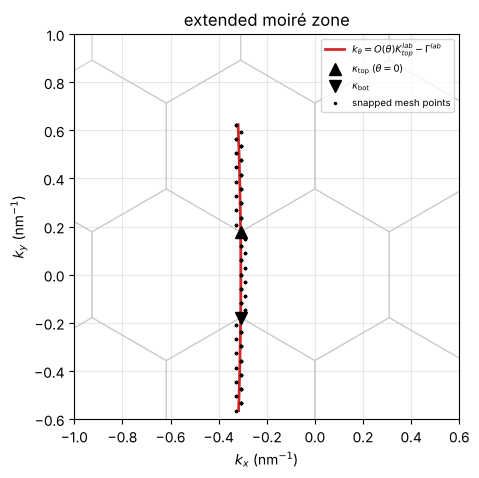

In [2]:
theta = np.linspace(-1.5, 2.5, 161)
traj = qtm.tbg_trajectory(tbg, theta)
print(f"max snapping error: {traj['snap_error'].max()/traj['mesh_spacing']:.2f} mesh spacings")
for t in (0.0, params.theta_deg, -params.theta_deg):
    k = qtm.tbg_tip_momentum(tbg, t)
    print(f"theta = {t:+.2f} deg: k = {np.round(k, 4)},  |k - K_top| = {np.linalg.norm(k-fr['K_top']):.4f},"
          f" |k - K_bot| = {np.linalg.norm(k-fr['K_bot']):.4f},  |k| = {np.linalg.norm(k):.4f} (|G_M| = {params.G_moire:.4f})")

B = fr["basis"]; G = params.G_moire
hexa = np.array([G / np.sqrt(3) * np.array([np.cos(a), np.sin(a)]) for a in np.deg2rad(np.arange(30, 391, 60))])
fig, ax = plt.subplots(figsize=(5.2, 5))
for m1 in range(-2, 3):
    for m2 in range(-2, 3):
        c = B @ np.array([m1, m2]); ax.plot(*(hexa + c).T, color="0.8", lw=0.8)
ax.plot(*traj["k_ext"].T, "C3-", lw=2, label=r"$k_\theta=O(\theta)K^{lab}_{top}-\Gamma^{lab}$")
ax.plot(*fr["K_top"], "k^", ms=8, label=r"$\kappa_{\rm top}$ ($\theta=0$)"); ax.plot(*fr["K_bot"], "kv", ms=8, label=r"$\kappa_{\rm bot}$")
km = np.asarray(tbg["k_sample"].coords)[traj["k_index"]] + traj["G_int"] @ B.T
ax.plot(*km.T, "k.", ms=3, label="snapped mesh points")
ax.set_aspect("equal"); ax.set_xlim(-1.0, 0.6); ax.set_ylim(-0.6, 1.0); ax.legend(fontsize=7, loc="upper right")
ax.set_xlabel(r"$k_x$ (nm$^{-1}$)"); ax.set_ylabel(r"$k_y$ (nm$^{-1}$)"); ax.set_title("extended moiré zone"); plt.show()

## 2. Validation: decoupled layers

With $u_{AA}=u_{AB}=0$ the tip couples only to the top layer, whose Dirac cone is centred at $\kappa_{\rm top}$
in the *extended* zone. The bare conductance must then follow $eV=\pm\hbar v|\mathbf{K}_\theta-\mathbf{K}_{\rm top}|=\pm2\hbar vK\sin(\theta/2)$
for every $\theta$, including outside the first moiré zone, because the amplitude $\Lambda$ is taken from the plane
wave that unfolds the momentum.

max |peak - hbar v |k - K_top|| over 59 angles: 0.23 meV


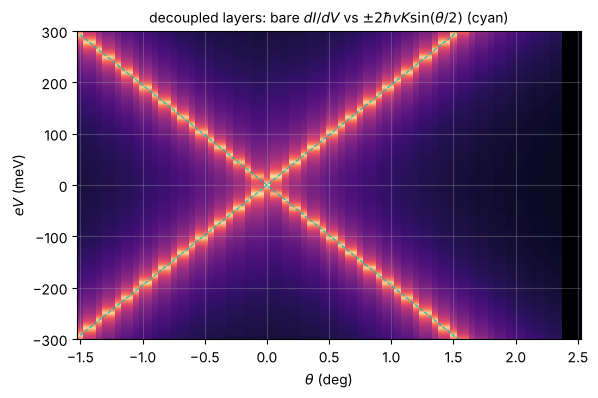

In [3]:
p0 = tm.TBGParams(theta_deg=1.20, uAB=1e-9, uAA_ratio=0.0, n_sites=24, n_bands=8, eta_override=2e-3)
tbg0 = tm.build_tbg(p0, verbose=False)
th0 = np.linspace(-1.5, 2.5, 81); ev = np.linspace(-0.3, 0.3, 1201)
tr0 = qtm.tbg_trajectory(tbg0, th0)
d0 = qtm.tbg_bare_didv(tbg0, tr0, ev, eta_qp=3e-3)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.pcolormesh(th0, ev * 1e3, np.log10(d0.T + 1e-2), shading="auto", cmap="magma", vmin=-2, vmax=2.5)
vline = p0.hv * qtm.twist_to_momentum(th0, p0.K)
ax.plot(th0, vline * 1e3, "c--", lw=0.8); ax.plot(th0, -vline * 1e3, "c--", lw=0.8)
ax.set_xlabel(r"$\theta$ (deg)"); ax.set_ylabel(r"$eV$ (meV)"); ax.set_ylim(-300, 300)
ax.set_title(r"decoupled layers: bare $dI/dV$ vs $\pm2\hbar vK\sin(\theta/2)$ (cyan)", fontsize=10); plt.show()
k_snap = np.asarray(tbg0["k_sample"].coords)[tr0["k_index"]] + tr0["G_int"] @ tm.model_frame(tbg0)["basis"].T
e_exp = p0.hv * np.linalg.norm(k_snap - tm.model_frame(tbg0)["K_top"], axis=1)
sel = e_exp < 0.29
e_peak = np.abs(ev[np.argmax(d0, axis=1)])
print(f"max |peak - hbar v |k - K_top|| over {sel.sum()} angles: {np.max(np.abs(e_peak[sel] - e_exp[sel]))*1e3:.2f} meV")

## 3. Interacting TBG: screened interaction and resolvent kernel

In [4]:
t0 = time.time()
lh = tm.build_layer_helper(tbg, verbose=False)
eta = params.eta
omega = np.linspace(2 * eta, 0.16, 320)
chi = tm.chi0_tbg(lh, omega + 1j * eta, verbose=False)
cfg = tst.TBGSLGConfig(tbg=params, d_tip=1.0, n_tip=0.0)
_, _, W = tst.build_stack_eps_W(cfg, np.asarray(tbg["q_sample"].coords), omega, chi, verbose=False)
S = tse.sample_spectral_density(W, hermitian=True)
eps_v = np.linspace(-0.15, 0.15, 601)                       # = eV axis
kernel = tse.build_kernel_tbg(tbg, S, omega, eps_v, eta_self=eta)
qw = tse.q_weights_tbg(tbg)
print(f"densityL, chi0, W and kernel: {time.time()-t0:.1f} s  ({cfg.label()})")

densityL, chi0, W and kernel: 140.0 s  (d_tip=1 nm, tip n=0 nm^-2, ungated, eps=(6.41,3), eps_gap=1)


## 4. Tunneling amplitudes and bare conductance (Wei *et al.* Fig. 4a)

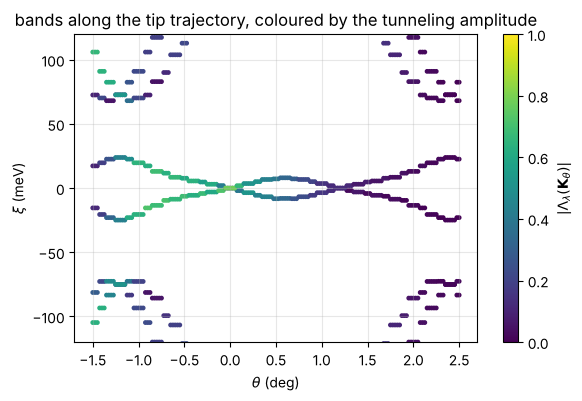

In [5]:
bands = list(range(2 * N_BANDS))
E = np.asarray(tbg["crystal"].band_structure.energies) - tbg["mu"]
Lam = np.array([qtm.tbg_tunneling_amplitudes(tbg, traj["k_index"][i], bands, G_int=tuple(traj["G_int"][i]))
                for i in range(theta.size)])
fig, ax = plt.subplots(figsize=(6.5, 4))
for n in bands:
    sc = ax.scatter(theta, E[n, traj["k_index"]] * 1e3, c=np.abs(Lam[:, n]), s=6, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(sc, label=r"$|\Lambda_\lambda(\mathbf{K}_\theta)|$")
ax.set_xlabel(r"$\theta$ (deg)"); ax.set_ylabel(r"$\xi$ (meV)"); ax.set_ylim(-120, 120)
ax.set_title("bands along the tip trajectory, coloured by the tunneling amplitude"); plt.show()

## 5. $dI/dV(V,\theta)$ and $d^2I/dV^2$ from the band-matrix G0W spectral function

Sigma at 36 distinct k points: 83.0 s


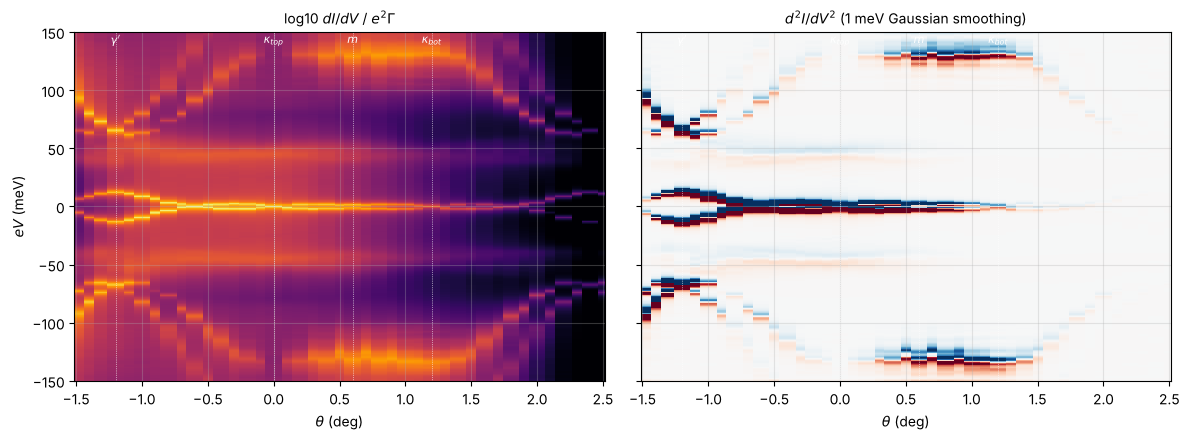

In [6]:
t0 = time.time()
spec = qtm.tbg_spectral_along_trajectory(tbg, lh, traj, None, None, qw, eps_v, kernel=kernel, eta_qp=0.5e-3)
res = qtm.tbg_didv(tbg, traj, spec)
didv = res["didv"]
d2 = qtm.bias_derivative(qtm.smooth_bias(didv, eps_v, 1.0e-3), eps_v)
print(f"Sigma at {spec['k_unique'].size} distinct k points: {time.time()-t0:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axs[0].pcolormesh(theta, eps_v * 1e3, np.log10(didv.T + 1e-3), shading="auto", cmap="inferno", vmin=-2.5, vmax=2.5)
axs[0].set_title(r"log10 $dI/dV$ / $e^2\Gamma$", fontsize=10)
lim = np.percentile(np.abs(d2), 97)
axs[1].pcolormesh(theta, eps_v * 1e3, d2.T, shading="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
axs[1].set_title(r"$d^2I/dV^2$ (1 meV Gaussian smoothing)", fontsize=10)
for a in axs:
    a.set_xlabel(r"$\theta$ (deg)")
    for t, lab in ((0, r"$\kappa_{top}$"), (params.theta_deg, r"$\kappa_{bot}$"), (-params.theta_deg, r"$\gamma'$"), (params.theta_deg / 2, r"$m$")):
        a.axvline(t, color="w", lw=0.5, ls=":"); a.text(t, 140, lab, color="w", ha="center", fontsize=8)
axs[0].set_ylabel(r"$eV$ (meV)"); plt.tight_layout(); plt.show()

## 6. Line cuts: quasiparticle peaks and plasmon satellites

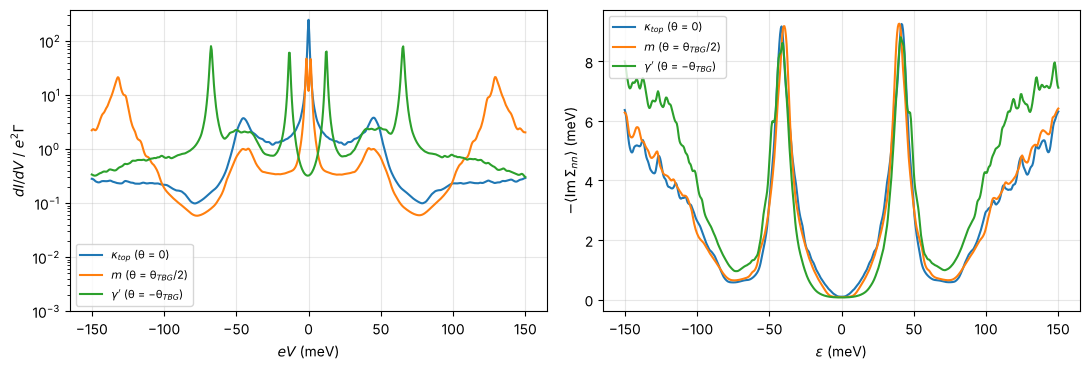

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for t, lab in ((0.0, r"$\kappa_{top}$ (θ = 0)"), (params.theta_deg / 2, r"$m$ (θ = θ$_{TBG}$/2)"), (-params.theta_deg, r"$\gamma'$ (θ = −θ$_{TBG}$)")):
    it = int(np.argmin(np.abs(theta - t)))
    ax[0].semilogy(eps_v * 1e3, didv[it], label=lab)
    iu = spec["inverse"][it]
    ax[1].plot(eps_v * 1e3, -np.einsum("nne->e", spec["Sigma"][iu].imag)[:] * 1e3 / len(bands), label=lab)
ax[0].set_xlabel(r"$eV$ (meV)"); ax[0].set_ylabel(r"$dI/dV$ / $e^2\Gamma$"); ax[0].legend(fontsize=8); ax[0].set_ylim(1e-3, None)
ax[1].set_xlabel(r"$\varepsilon$ (meV)"); ax[1].set_ylabel(r"$-\langle\mathrm{Im}\,\Sigma_{nn}\rangle$ (meV)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. How much the interband self-energy matters

The band-diagonal approximation keeps only $\Sigma_{\lambda\lambda}$. Comparing it with the full band matrix shows
where the interband (off-diagonal) self-energy changes the conductance: where bands are closer than $|\Sigma|$.

relative L2 difference band matrix vs band-diagonal dI/dV: 0.1007689116857747


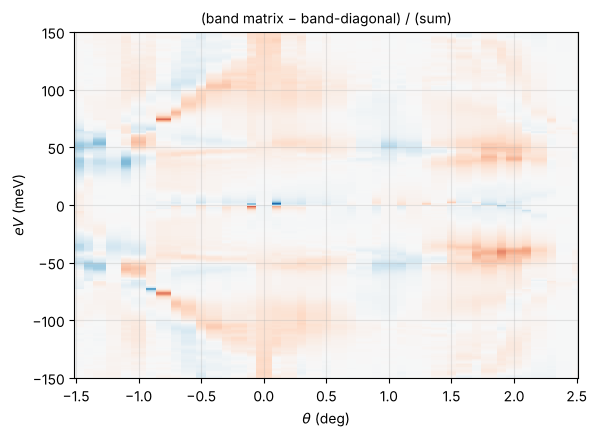

In [8]:
spec_diag = qtm.tbg_spectral_along_trajectory(tbg, lh, traj, None, None, qw, eps_v, kernel=kernel,
                                              band_diagonal=True, eta_qp=0.5e-3)
didv_diag = qtm.tbg_didv(tbg, traj, spec_diag)["didv"]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
rel = (didv - didv_diag) / (didv + didv_diag + 1e-2)
ax.pcolormesh(theta, eps_v * 1e3, rel.T, shading="auto", cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax.set_title("(band matrix − band-diagonal) / (sum)", fontsize=10)
ax.set_xlabel(r"$\theta$ (deg)"); ax.set_ylabel(r"$eV$ (meV)"); plt.show()
print("relative L2 difference band matrix vs band-diagonal dI/dV:", np.linalg.norm(didv - didv_diag) / np.linalg.norm(didv))